# Notebook 03 — Exploratory Data Analysis (EDA)


## 1. Import libraries and configure paths

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Pandas version: 3.1.0
NumPy version: 2.4.6


In [2]:
cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "processed").is_dir() and cwd.name.lower() == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = next(
        (p for p in [cwd, *cwd.parents] if (p / "data" / "processed").is_dir()),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed. Run Notebook 02 first and open this notebook "
        "from the project root or notebooks/ folder."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EDA_OUTPUT_DIR = PROCESSED_DIR / "eda"
EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

processed_candidates = [
    p for p in PROCESSED_DIR.glob("usgs_earthquakes_cleaned_*.csv")
    if p.is_file()
]
if not processed_candidates:
    raise FileNotFoundError(
        f"No cleaned CSV matching 'usgs_earthquakes_cleaned_*.csv' found in {PROCESSED_DIR}. "
        "Run Notebook 02 successfully first."
    )

processed_file = max(processed_candidates, key=lambda p: p.stat().st_mtime)
print("Project root:", PROJECT_ROOT)
print("Selected cleaned file:", processed_file.name)


Project root: D:\global seismic trends
Selected cleaned file: usgs_earthquakes_cleaned_20261022T134538Z.csv


## 2. Load the cleaned dataset

In [3]:
df = pd.read_csv(processed_file, low_memory=False)

# Re-parse timestamps because CSV stores datetime values as text.
if "time" in df.columns:
    df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
if "updated" in df.columns:
    df["updated"] = pd.to_datetime(df["updated"], utc=True, errors="coerce")

numeric_cols = [
    "latitude", "longitude", "depth_km", "mag", "tsunami", "sig", "nst",
    "dmin", "rms", "gap", "magError", "depthError", "magNst",
    "year", "month", "day", "hour_utc"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print("Time range (UTC):", df["time"].min(), "to", df["time"].max())
display(df.head())


Rows: 739,554
Columns: 51
Time range (UTC): 2021-10-22 13:22:28.170000+00:00 to 2026-10-22 13:13:42.330000+00:00


,id,time,updated,latitude,longitude,depth_km,mag,magType,place,status,tsunami,sig,net,nst,dmin,rms,gap,magError,depthError,magNst,locationSource,magSource,types,ids,sources,type,alert,felt,cdi,mmi,url,detail,place_type,time_zone,is_invalid_latitude,is_invalid_longitude,has_invalid_coordinates,is_negative_depth,is_extreme_depth_over_700km,is_magnitude_outside_review_range,has_missing_magnitude,has_missing_timestamp,year,month,day,day_of_week,hour_utc,date_utc,depth_category,magnitude_category,place_region_text
0,nc73642735,2021-10-22 13:22:28.170+00:00,2021-10-22 15:26:11.754+00:00,38.808,-122.814,0.080,0.840,md,"6km NW of The Geysers, CA",automatic,0,11,nc,11.000,0.012,0.020,77.000,NaN,NaN,NaN,NaN,NaN,",nearby-cities,origin,phase-data,scitech-link,",",nc73642735,",",nc,",earthquake,NaN,NaN,NaN,NaN,https://earthquake.usgs.gov/earthquakes/eventpage/nc73642735,https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=nc73642735&format=geojson,NaN,NaN,False,False,False,False,False,False,False,False,2021,10,22,Friday,13,2021-10-22,Shallow (<70 km),Below 2.0,"NW of The Geysers, CA"
1,mb80527769,2021-10-22 13:27:15.120+00:00,2021-10-22 15:21:51.820+00:00,47.839,-114.289,3.170,-0.200,ml,"3 km SSW of Dayton, Montana",reviewed,0,0,mb,6.000,0.093,0.040,169.000,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",mb80527769,",",mb,",earthquake,NaN,NaN,NaN,NaN,https://earthquake.usgs.gov/earthquakes/eventpage/mb80527769,https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=mb80527769&format=geojson,NaN,NaN,False,False,False,False,False,False,False,False,2021,10,22,Friday,13,2021-10-22,Shallow (<70 km),Below 2.0,"SSW of Dayton, Montana"
2,mb80527774,2021-10-22 13:31:59.150+00:00,2021-10-22 15:28:57.720+00:00,47.767,-113.754,3.910,0.560,ml,"19 km SSE of Swan Lake, Montana",reviewed,0,5,mb,7.000,0.199,0.110,148.000,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",mb80527774,",",mb,",earthquake,NaN,NaN,NaN,NaN,https://earthquake.usgs.gov/earthquakes/eventpage/mb80527774,https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=mb80527774&format=geojson,NaN,NaN,False,False,False,False,False,False,False,False,2021,10,22,Friday,13,2021-10-22,Shallow (<70 km),Below 2.0,"SSE of Swan Lake, Montana"
3,ak021dk3jgyc,2021-10-22 13:44:11.726+00:00,2021-12-06 18:54:05.882+00:00,59.679,-136.572,24.000,1.200,ml,"31 km WNW of Mosquito Lake, Alaska",reviewed,0,22,ak,NaN,NaN,0.260,NaN,NaN,NaN,NaN,NaN,NaN,",origin,phase-data,",",ak021dk3jgyc,",",ak,",earthquake,NaN,NaN,NaN,NaN,https://earthquake.usgs.gov/earthquakes/eventpage/ak021dk3jgyc,https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=ak021dk3jgyc&format=geojson,NaN,NaN,False,False,False,False,False,False,False,False,2021,10,22,Friday,13,2021-10-22,Shallow (<70 km),Below 2.0,"WNW of Mosquito Lake, Alaska"
4,ci39840223,2021-10-22 13:55:21.010+00:00,2021-10-22 17:59:28.696+00:00,33.344,-116.928,18.040,0.790,ml,"6km WSW of Palomar Observatory, CA",reviewed,0,10,ci,25.000,0.056,0.150,48.000,NaN,NaN,NaN,NaN,NaN,",nearby-cities,origin,phase-data,scitech-link,",",ci39840223,",",ci,",earthquake,NaN,NaN,NaN,NaN,https://earthquake.usgs.gov/earthquakes/eventpage/ci39840223,https://earthquake.usgs.gov/fdsnws/event/1/query?eventid=ci39840223&format=geojson,NaN,NaN,False,False,False,False,False,False,False,False,2021,10,22,Friday,13,2021-10-22,Shallow (<70 km),Below 2.0,"WSW of Palomar Observatory, CA"


## 3. Dataset overview and data quality

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
display(overview)

quality_checks = {
    "rows": int(len(df)),
    "unique_event_ids": int(df["id"].nunique()) if "id" in df.columns else None,
    "duplicate_non_missing_ids": int(df.loc[df["id"].notna(), "id"].duplicated().sum()) if "id" in df.columns else None,
    "missing_event_ids": int(df["id"].isna().sum()) if "id" in df.columns else None,
    "missing_timestamps": int(df["time"].isna().sum()) if "time" in df.columns else None,
    "invalid_coordinates": int(
        ((~df["latitude"].between(-90, 90)) & df["latitude"].notna()
         | (~df["longitude"].between(-180, 180)) & df["longitude"].notna()).sum()
    ) if {"latitude", "longitude"}.issubset(df.columns) else None
}
display(pd.Series(quality_checks, name="value").to_frame())


,dtype,non_null_count,missing_count,missing_percent
id,str,739554,0,0.000
time,"datetime64[us, UTC]",739554,0,0.000
updated,"datetime64[us, UTC]",739554,0,0.000
latitude,float64,739554,0,0.000
longitude,float64,739554,0,0.000
depth_km,float64,739554,0,0.000
mag,float64,739497,57,0.010
magType,str,739497,57,0.010
place,str,739554,0,0.000
status,str,739554,0,0.000


,value
rows,739554
unique_event_ids,739554
duplicate_non_missing_ids,0
missing_event_ids,0
missing_timestamps,0
invalid_coordinates,0


## 4. Earthquake frequency over time


In [5]:
valid_time = df.loc[df["time"].notna()].copy()
valid_time["year_month"] = valid_time["time"].dt.to_period("M").astype(str)

events_by_year = (
    valid_time.groupby(valid_time["time"].dt.year)
    .size().rename("earthquake_count").rename_axis("year").reset_index()
)
events_by_month = (
    valid_time.groupby("year_month")
    .size().rename("earthquake_count").reset_index()
)

display(events_by_year)
display(events_by_month.head(12))


C:\Users\itach\AppData\Local\Temp\ipykernel_17524\1152395439.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  valid_time["year_month"] = valid_time["time"].dt.to_period("M").astype(str)


,year,earthquake_count
0,2021,26767
1,2022,150752
2,2023,151618
3,2024,155899
4,2025,140351
5,2026,114167


,year_month,earthquake_count
0,2021-10,3784
1,2021-11,11583
2,2021-12,11400
3,2022-01,12954
4,2022-02,11769
5,2022-03,12804
6,2022-04,12430
7,2022-05,12167
8,2022-06,11854
9,2022-07,12233


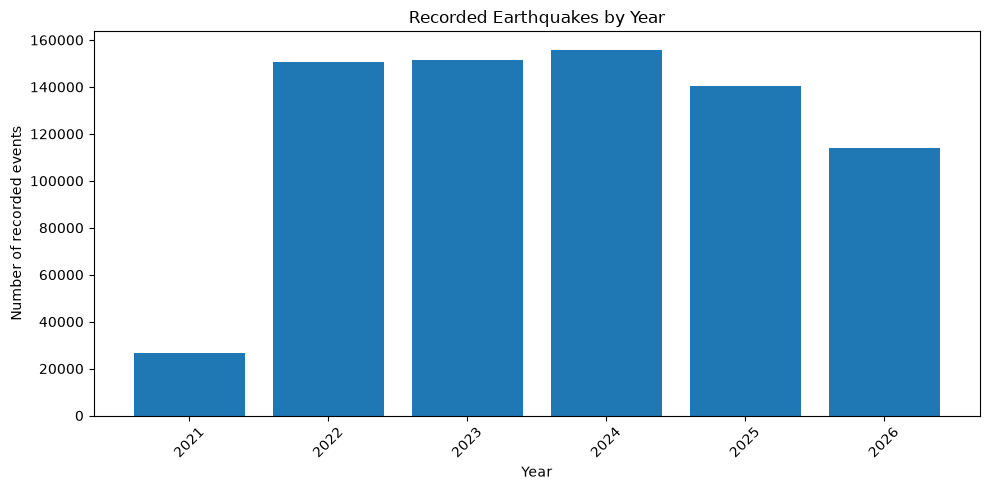

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(events_by_year["year"].astype(str), events_by_year["earthquake_count"])
ax.set_title("Recorded Earthquakes by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of recorded events")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()


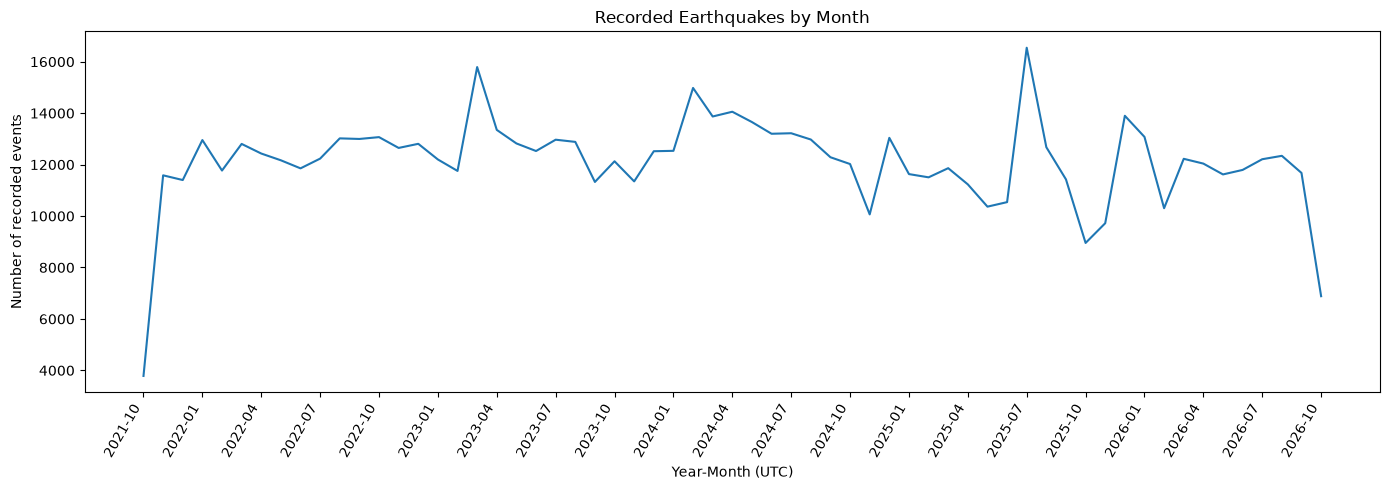

In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(events_by_month["year_month"], events_by_month["earthquake_count"])
ax.set_title("Recorded Earthquakes by Month")
ax.set_xlabel("Year-Month (UTC)")
ax.set_ylabel("Number of recorded events")
tick_step = max(1, len(events_by_month) // 18)
ax.set_xticks(range(0, len(events_by_month), tick_step))
ax.set_xticklabels(events_by_month["year_month"].iloc[::tick_step], rotation=60, ha="right")
fig.tight_layout()
plt.show()


## 5. Magnitude distribution and strongest events

Records with magnitude: 739,497


,count,mean,std,min,25%,50%,75%,max
magnitude,"739,497.000",1.658,1.298,-5.000,0.850,1.400,2.100,8.800


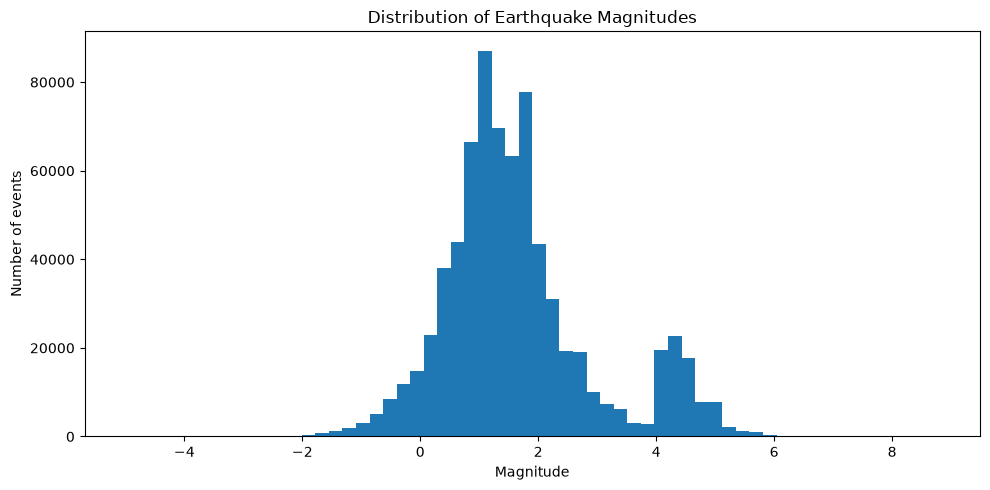

,time,mag,magType,depth_km,place,latitude,longitude,tsunami,sig
0,2025-07-29 23:24:52.483+00:00,8.800,mww,35.000,"2025 Kamchatka Peninsula, Russia Earthquake",52.495,160.239,1,2114
1,2023-02-06 01:17:34.342+00:00,7.800,mww,10.000,"Pazarcik earthquake, Kahramanmaras earthquake sequence",37.226,37.014,0,2910
2,2025-09-18 18:58:14.939+00:00,7.800,mww,27.000,"140 km E of Petropavlovsk-Kamchatsky, Russia",53.143,160.721,1,1021
3,2026-06-07 23:37:41.970+00:00,7.800,mww,56.991,"25 km SW of Kablalan, Philippines",5.599,125.056,0,1571
4,2026-08-14 21:58:21.561+00:00,7.800,mww,10.000,"66 km NNW of Ende, Indonesia",-8.336,121.345,0,1059
5,2023-05-19 02:57:03.172+00:00,7.700,mww,18.053,southeast of the Loyalty Islands,-23.206,170.742,1,935
6,2025-03-28 06:20:52.715+00:00,7.700,mww,10.000,"2025 Mandalay, Burma (Myanmar) Earthquake",22.011,95.936,0,2910
7,2026-10-09 17:56:06.036+00:00,7.700,mww,12.647,"12 km WSW of Pitaloza Arriba, Panama",7.587,-80.769,0,1790
8,2022-09-10 23:47:00.233+00:00,7.600,mww,116.000,"70 km E of Kainantu, Papua New Guinea",-6.294,146.504,1,965
9,2022-09-19 18:05:08.217+00:00,7.600,mww,26.943,"35 km SSW of Aguililla, Mexico",18.455,-102.956,1,1719


In [8]:
if "mag" in df.columns:
    valid_mag = df.loc[df["mag"].notna(), "mag"]
    print("Records with magnitude:", f"{len(valid_mag):,}")
    display(valid_mag.describe().to_frame("magnitude").T)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(valid_mag, bins=60)
    ax.set_title("Distribution of Earthquake Magnitudes")
    ax.set_xlabel("Magnitude")
    ax.set_ylabel("Number of events")
    fig.tight_layout()
    plt.show()

    top_earthquakes = df.loc[df["mag"].notna()].nlargest(20, "mag")
    top_cols = [c for c in ["time", "mag", "magType", "depth_km", "place", "latitude", "longitude", "tsunami", "sig"] if c in df.columns]
    display(top_earthquakes[top_cols].reset_index(drop=True))
else:
    print("Magnitude field is not available.")


## 6. Depth distribution and magnitude versus depth

Records with depth: 739,554


,count,mean,std,min,25%,50%,75%,max
depth_km,"739,554.000",24.519,55.651,-10.000,3.480,8.356,18.100,683.578


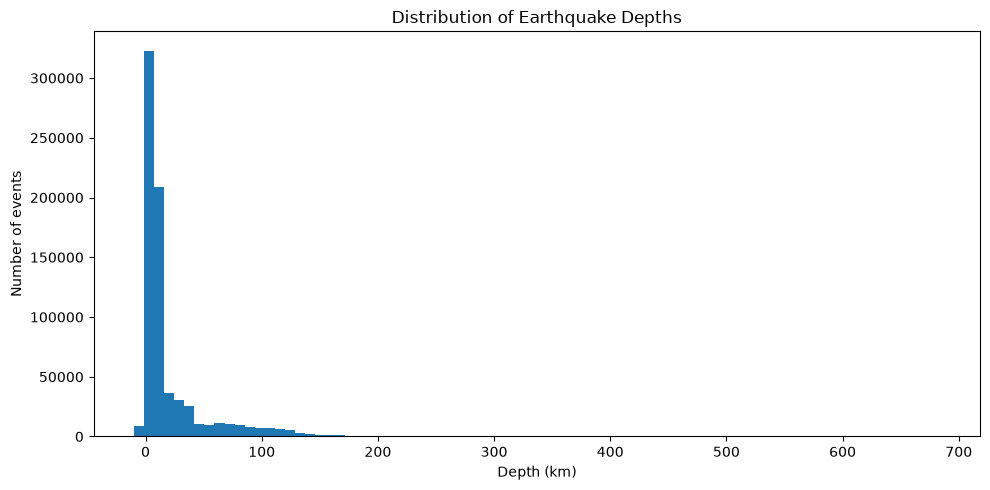

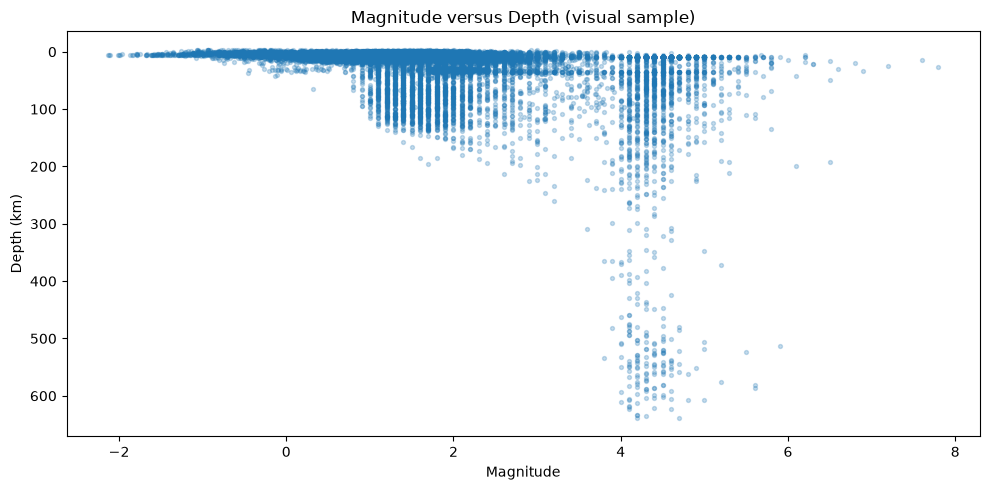

In [9]:
if "depth_km" in df.columns:
    valid_depth = df.loc[df["depth_km"].notna(), "depth_km"]
    print("Records with depth:", f"{len(valid_depth):,}")
    display(valid_depth.describe().to_frame("depth_km").T)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(valid_depth, bins=80)
    ax.set_title("Distribution of Earthquake Depths")
    ax.set_xlabel("Depth (km)")
    ax.set_ylabel("Number of events")
    fig.tight_layout()
    plt.show()

if {"mag", "depth_km"}.issubset(df.columns):
    scatter_data = df.loc[df["mag"].notna() & df["depth_km"].notna(), ["mag", "depth_km"]]
    if len(scatter_data) > 20000:
        scatter_data = scatter_data.sample(n=20000, random_state=42)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(scatter_data["mag"], scatter_data["depth_km"], alpha=0.25, s=8)
    ax.set_title("Magnitude versus Depth (visual sample)")
    ax.set_xlabel("Magnitude")
    ax.set_ylabel("Depth (km)")
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()


## 7. Depth and magnitude category summaries

In [10]:
for col in ["depth_category", "magnitude_category"]:
    if col in df.columns:
        category_summary = (
            df[col].fillna("Missing").value_counts(dropna=False)
            .rename_axis(col).rename("event_count").reset_index()
        )
        category_summary["percent"] = (category_summary["event_count"] / len(df) * 100).round(2)
        display(category_summary)


,depth_category,event_count,percent
0,Shallow (<70 km),642745,86.910
1,Intermediate (70-300 km),65744,8.890
2,Review - negative,25047,3.390
3,Deep (>300 km),6018,0.810


,magnitude_category,event_count,percent
0,Below 2.0,525467,71.050
1,2.0-2.9,110351,14.920
2,4.0-4.9,71356,9.650
3,3.0-3.9,23138,3.130
4,5.0-5.9,8448,1.140
5,6.0-6.9,591,0.080
6,Review - unusual magnitude,75,0.010
7,7.0+,71,0.010
8,Missing,57,0.010


## 8. Hour-of-day and day-of-week patterns

,hour_utc_eda,event_count
0,0,30550
1,1,30191
2,2,30836
3,3,30991
4,4,31386
5,5,31466
6,6,31683
7,7,32045
8,8,32403
9,9,32221


,day_of_week,event_count
0,Monday,105986
1,Tuesday,105632
2,Wednesday,106762
3,Thursday,106701
4,Friday,105916
5,Saturday,104094
6,Sunday,104463


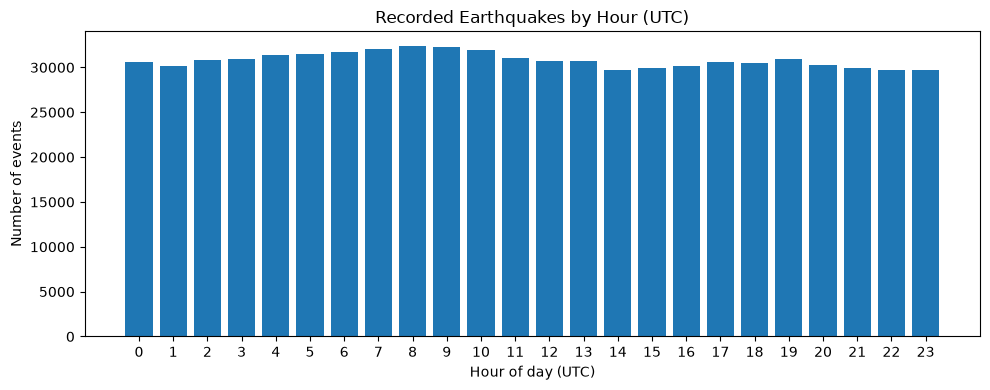

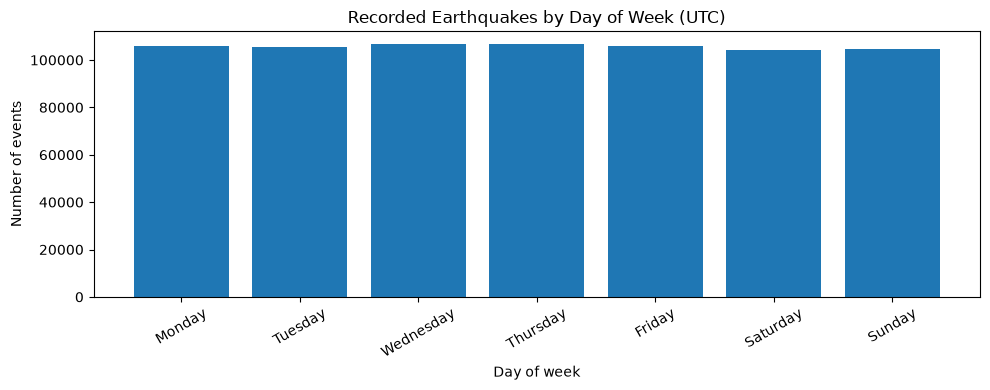

In [11]:
if "time" in df.columns:
    timed = df.loc[df["time"].notna()].copy()
    timed["hour_utc_eda"] = timed["time"].dt.hour
    timed["day_of_week_eda"] = timed["time"].dt.day_name()

    events_by_hour = timed.groupby("hour_utc_eda").size().reindex(range(24), fill_value=0).rename("event_count").reset_index()
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    events_by_weekday = timed["day_of_week_eda"].value_counts().reindex(day_order, fill_value=0).rename("event_count").rename_axis("day_of_week").reset_index()

    display(events_by_hour)
    display(events_by_weekday)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(events_by_hour["hour_utc_eda"], events_by_hour["event_count"])
    ax.set_title("Recorded Earthquakes by Hour (UTC)")
    ax.set_xlabel("Hour of day (UTC)")
    ax.set_ylabel("Number of events")
    ax.set_xticks(range(24))
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(events_by_weekday["day_of_week"], events_by_weekday["event_count"])
    ax.set_title("Recorded Earthquakes by Day of Week (UTC)")
    ax.set_xlabel("Day of week")
    ax.set_ylabel("Number of events")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    plt.show()


## 9. Tsunami-associated events and significance

In [12]:
if "tsunami" in df.columns:
    tsunami_counts = (
        df["tsunami"].map({0: "No tsunami flag", 1: "Tsunami flag = 1"})
        .fillna("Missing / other")
        .value_counts()
        .rename_axis("tsunami_flag").rename("event_count").reset_index()
    )
    tsunami_counts["percent_of_all_records"] = (tsunami_counts["event_count"] / len(df) * 100).round(4)
    display(tsunami_counts)

    tsunami_events = df.loc[df["tsunami"] == 1].copy()
    print("Records with tsunami flag = 1:", f"{len(tsunami_events):,}")
    display(tsunami_events[[c for c in ["time", "mag", "depth_km", "place", "sig", "status"] if c in df.columns]].head(20))

if "sig" in df.columns:
    print("Significance score summary:")
    display(df["sig"].describe().to_frame("sig").T)

    if "mag" in df.columns:
        sig_mag = df.loc[df["sig"].notna() & df["mag"].notna(), ["sig", "mag"]]
        if len(sig_mag) > 1:
            print("Pearson correlation between magnitude and significance (descriptive only):",
                  round(sig_mag["sig"].corr(sig_mag["mag"]), 4))


,tsunami_flag,event_count,percent_of_all_records
0,No tsunami flag,738969,99.921
1,Tsunami flag = 1,585,0.079


Records with tsunami flag = 1: 585


,time,mag,depth_km,place,sig,status
1382,2021-10-25 23:42:35.860+00:00,4.650,7.790,"18km NW of San Simeon, CA",568,reviewed
3678,2021-10-31 16:37:46.017+00:00,5.600,25.000,"115 km SSE of Perryville, Alaska",484,reviewed
4659,2021-11-03 00:24:51.300+00:00,4.380,29.600,"5km NNE of Petrolia, CA",350,reviewed
5162,2021-11-04 08:57:06.935+00:00,5.200,39.300,"69 km ESE of Nikolski, Alaska",417,reviewed
7600,2021-11-10 15:45:13.652+00:00,6.600,12.000,"177 km SE of Hirara, Japan",689,reviewed
7968,2021-11-11 18:58:50.771+00:00,4.000,110.400,"57 km ESE of Pedro Bay, Alaska",246,reviewed
11284,2021-11-20 05:51:29.357+00:00,4.600,10.000,off the coast of Oregon,328,reviewed
14404,2021-11-28 10:52:14.579+00:00,7.500,126.000,"43 km NNW of Barranca, Peru",1094,reviewed
14801,2021-11-29 12:40:44.400+00:00,6.300,11.000,"Izu Islands, Japan region",657,reviewed
17999,2021-12-07 21:30:16.386+00:00,5.500,10.000,off the coast of Oregon,468,reviewed


Significance score summary:


,count,mean,std,min,25%,50%,75%,max
sig,"739,554.000",68.361,98.658,0.000,11.000,30.000,68.000,"2,910.000"


Pearson correlation between magnitude and significance (descriptive only): 0.9197


## 10. Geographic patterns using coordinates

Most populated coordinate bins (0.5-degree grid):


,latitude_bin,longitude_bin,event_count
10248,38.500,-123.000,76280
7140,19.000,-155.500,31374
8515,31.500,-104.500,14442
8865,33.500,-117.000,13348
13546,58.000,-155.500,12920
8768,33.000,-116.500,9819
9387,35.500,-97.000,9321
13890,61.000,-152.500,8489
6965,17.500,-67.000,7765
9359,35.500,-118.000,7664


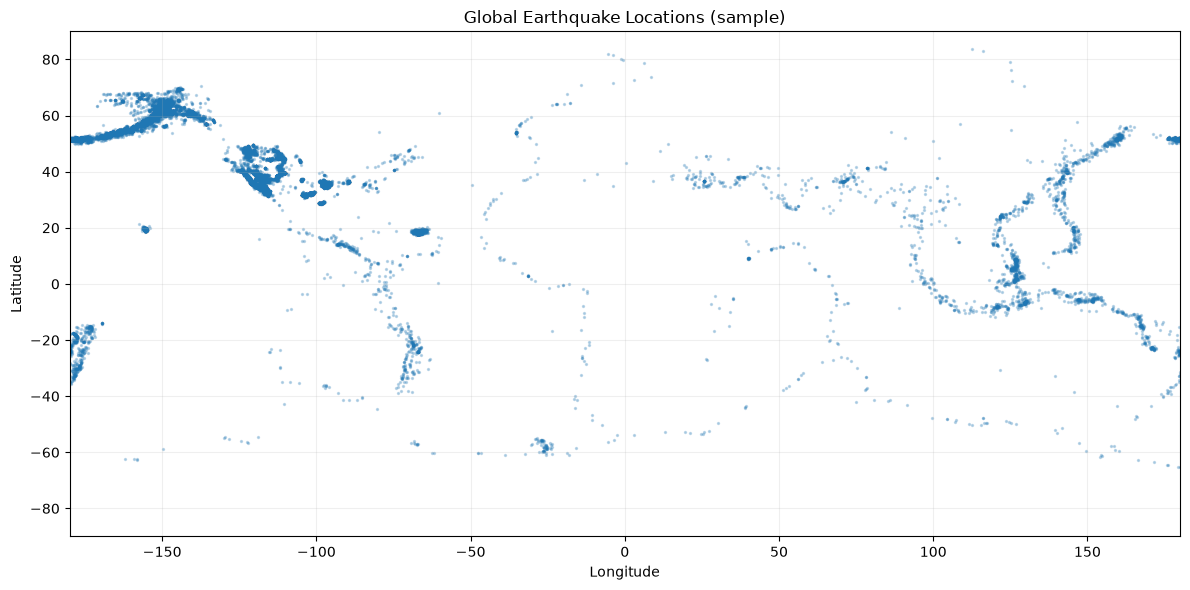

In [13]:
if {"latitude", "longitude"}.issubset(df.columns):
    geo = df.loc[
        df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180),
        ["latitude", "longitude"]
    ].dropna().copy()

    # Half-degree bins are a simple exploratory grid, not official geographic regions.
    geo["latitude_bin"] = (np.floor(geo["latitude"] * 2) / 2).round(1)
    geo["longitude_bin"] = (np.floor(geo["longitude"] * 2) / 2).round(1)

    geo_hotspots = (
        geo.groupby(["latitude_bin", "longitude_bin"])
        .size().rename("event_count").reset_index()
        .sort_values("event_count", ascending=False)
    )
    print("Most populated coordinate bins (0.5-degree grid):")
    display(geo_hotspots.head(20))

    # A sampled coordinate scatterplot keeps the notebook responsive.
    geo_plot = geo.sample(n=min(30000, len(geo)), random_state=42) if len(geo) else geo
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.scatter(geo_plot["longitude"], geo_plot["latitude"], s=2, alpha=0.25)
    ax.set_title("Global Earthquake Locations (sample)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.grid(True, alpha=0.2)
    fig.tight_layout()
    plt.show()


## 11. Correlation analysis

,mag,depth_km,sig,nst,dmin,rms,gap,magError,depthError,magNst
mag,1.000,0.357,0.920,0.524,0.496,0.598,-0.037,NaN,NaN,NaN
depth_km,0.357,1.000,0.345,0.213,0.222,0.298,-0.011,NaN,NaN,NaN
sig,0.920,0.345,1.000,0.540,0.541,0.555,-0.015,NaN,NaN,NaN
nst,0.524,0.213,0.540,1.000,0.192,0.351,-0.356,NaN,NaN,NaN
dmin,0.496,0.222,0.541,0.192,1.000,0.399,0.014,NaN,NaN,NaN
rms,0.598,0.298,0.555,0.351,0.399,1.000,0.025,NaN,NaN,NaN
gap,-0.037,-0.011,-0.015,-0.356,0.014,0.025,1.000,NaN,NaN,NaN
magError,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
depthError,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
magNst,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


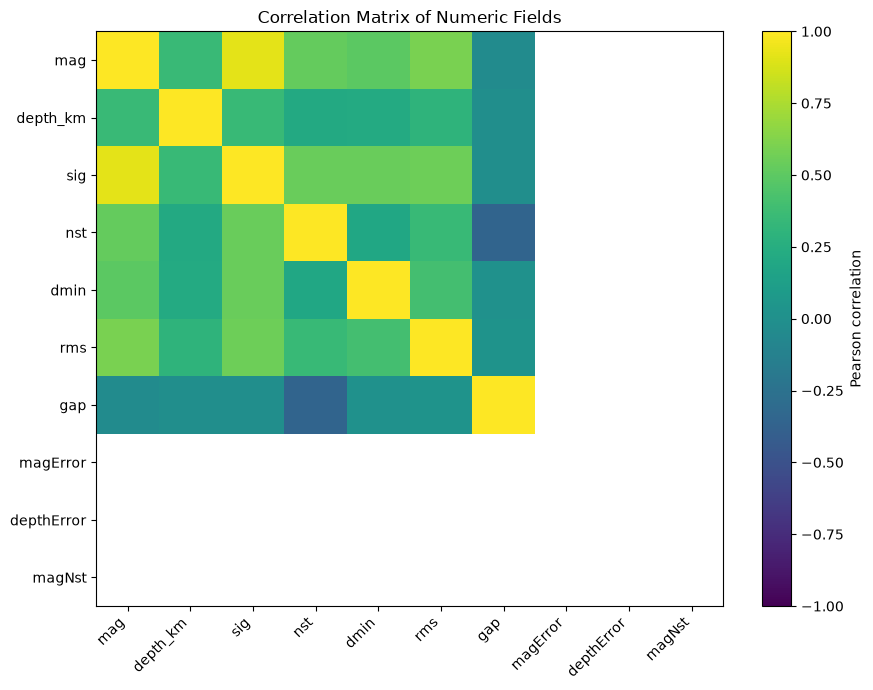

In [14]:
corr_cols = [c for c in ["mag", "depth_km", "sig", "nst", "dmin", "rms", "gap", "magError", "depthError", "magNst"] if c in df.columns]
corr_data = df[corr_cols].apply(pd.to_numeric, errors="coerce") if corr_cols else pd.DataFrame()

if len(corr_cols) >= 2:
    corr_matrix = corr_data.corr(numeric_only=True)
    display(corr_matrix)

    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(corr_matrix, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr_matrix.index)))
    ax.set_yticklabels(corr_matrix.index)
    ax.set_title("Correlation Matrix of Numeric Fields")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns available for correlation analysis.")


## 12. Summary tables for dashboard planning

In [15]:
dashboard_kpis = {
    "total_records": int(len(df)),
    "unique_event_ids": int(df["id"].nunique()) if "id" in df.columns else None,
    "events_with_magnitude": int(df["mag"].notna().sum()) if "mag" in df.columns else None,
    "events_magnitude_5_plus": int((df["mag"] >= 5).sum()) if "mag" in df.columns else None,
    "events_magnitude_7_plus": int((df["mag"] >= 7).sum()) if "mag" in df.columns else None,
    "events_depth_over_300km": int((df["depth_km"] > 300).sum()) if "depth_km" in df.columns else None,
    "tsunami_flagged_events": int((df["tsunami"] == 1).sum()) if "tsunami" in df.columns else None,
    "negative_depth_flagged_events": int(df["is_negative_depth"].fillna(False).sum()) if "is_negative_depth" in df.columns else None,
    "start_time_utc": df["time"].min().isoformat() if "time" in df.columns and df["time"].notna().any() else None,
    "end_time_utc": df["time"].max().isoformat() if "time" in df.columns and df["time"].notna().any() else None,
    "mean_magnitude": float(df["mag"].mean()) if "mag" in df.columns and df["mag"].notna().any() else None,
    "maximum_magnitude": float(df["mag"].max()) if "mag" in df.columns and df["mag"].notna().any() else None
}
display(pd.Series(dashboard_kpis, name="value").to_frame())


,value
total_records,739554
unique_event_ids,739554
events_with_magnitude,739497
events_magnitude_5_plus,9110
events_magnitude_7_plus,71
events_depth_over_300km,6018
tsunami_flagged_events,585
negative_depth_flagged_events,25047
start_time_utc,2021-10-22T13:22:28.170000+00:00
end_time_utc,2026-10-22T13:13:42.330000+00:00


## 13. Export EDA tables and findings metadata

In [16]:
run_timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

tables_to_save = {
    "events_by_year": events_by_year if "events_by_year" in globals() else None,
    "events_by_month": events_by_month if "events_by_month" in globals() else None,
    "events_by_hour_utc": events_by_hour if "events_by_hour" in globals() else None,
    "events_by_weekday": events_by_weekday if "events_by_weekday" in globals() else None,
    "geo_hotspots": geo_hotspots if "geo_hotspots" in globals() else None,
}

saved_tables = []
for table_name, table in tables_to_save.items():
    if isinstance(table, pd.DataFrame):
        output_path = EDA_OUTPUT_DIR / f"{table_name}_{run_timestamp}.csv"
        table.to_csv(output_path, index=False, encoding="utf-8")
        saved_tables.append(str(output_path))

eda_metadata = {
    "project": "Global Seismic Trends: Data-Driven Earthquake Insights",
    "notebook": "03_exploratory_data_analysis.ipynb",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_file": str(processed_file),
    "rows_analyzed": int(len(df)),
    "columns_analyzed": int(len(df.columns)),
    "kpis": dashboard_kpis,
    "summary_tables": saved_tables,
    "interpretation_note": "Descriptive analysis only; correlations and patterns do not establish causation."
}
metadata_path = EDA_OUTPUT_DIR / f"eda_metadata_{run_timestamp}.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(eda_metadata, f, indent=2, ensure_ascii=False, default=str)

print("EDA output directory:", EDA_OUTPUT_DIR)
print("Summary tables saved:", len(saved_tables))
for item in saved_tables:
    print("-", item)
print("Metadata saved:", metadata_path)


EDA output directory: D:\global seismic trends\data\processed\eda
Summary tables saved: 5
- D:\global seismic trends\data\processed\eda\events_by_year_20261022T140231Z.csv
- D:\global seismic trends\data\processed\eda\events_by_month_20261022T140231Z.csv
- D:\global seismic trends\data\processed\eda\events_by_hour_utc_20261022T140231Z.csv
- D:\global seismic trends\data\processed\eda\events_by_weekday_20261022T140231Z.csv
- D:\global seismic trends\data\processed\eda\geo_hotspots_20261022T140231Z.csv
Metadata saved: D:\global seismic trends\data\processed\eda\eda_metadata_20261022T140231Z.json
